# 第11章　ベイズ最適化・能動学習の発展

手法を選ぶ前に、観測できるもの、決めるもの、評価するものを定義します。ここでは多目的のPareto支配とハイパーボリューム、観測と介入の違いを独立した小例で計算します。これらは獲得関数や最適化器の性能比較ではありません。

非支配: ['A', 'B', 'D', 'E']
HV: 37.0 Dが加えるHV: 6.0


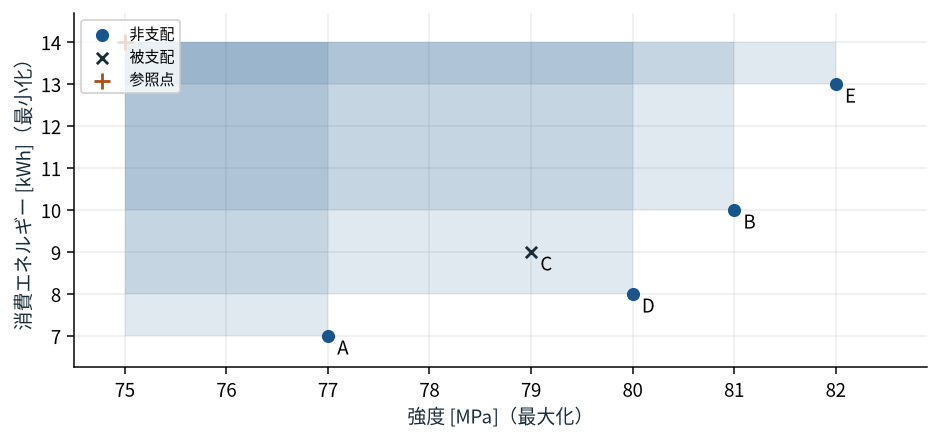

In [1]:
import json
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
from botorch.utils.multi_objective.hypervolume import Hypervolume
from botorch.utils.multi_objective.pareto import is_non_dominated

from experiment import BLUE, DTYPE, INK, ORANGE, QUALITY, SEED, save_figure, setup

setup()
torch.set_default_dtype(DTYPE)
names = "ABCDE"
strength = torch.tensor([77.0, 81.0, 79.0, 80.0, 82.0])
energy = torch.tensor([7.0, 10.0, 9.0, 8.0, 13.0])
objectives = torch.stack((strength, -energy), dim=-1)
pareto = is_non_dominated(objectives)
reference = torch.tensor([75.0, -14.0])
hv = Hypervolume(ref_point=reference)
volume = hv.compute(objectives[pareto])
mask_without_d = pareto.clone()
mask_without_d[3] = False
gain = volume - hv.compute(objectives[mask_without_d])
assert volume == 37.0 and gain == 6.0
print("非支配:", [name for name, keep in zip(names, pareto) if keep])
print("HV:", volume, "Dが加えるHV:", gain)

fig, ax = plt.subplots(figsize=(6.85, 3.15), layout="constrained")
for x, y in zip(strength[pareto], energy[pareto]):
    ax.add_patch(Rectangle((75, float(y)), float(x - 75), float(14 - y),
                           color=BLUE, alpha=0.13, linewidth=0))
ax.scatter(strength[pareto], energy[pareto], c=BLUE, label="非支配")
ax.scatter(strength[~pareto], energy[~pareto], c=INK, marker="x", label="被支配")
ax.scatter(75, 14, c=ORANGE, marker="+", s=72, label="参照点")
for name, x, y in zip(names, strength, energy):
    ax.annotate(name, (x, y), xytext=(5, -10), textcoords="offset points")
ax.set(xlabel="強度 [MPa]（最大化）", ylabel="消費エネルギー [kWh]（最小化）",
       xlim=(74.5, 82.9), ylim=(6.25, 14.7))
ax.legend(loc="upper left", fontsize=8)
save_figure(fig, "ch11_pareto")

## 11.2 固定したロット条件で決める

操作 $x$ と事前に測れる状況 $c$ が、ともに0か1の小例です。効用表の行が $c$、列が $x$ です。観測済みの $c$ で列を選ぶときの効用と、運用の前に一つの列を定めるときの効用を比べます。ここでは各状況が等確率で現れます。

In [2]:
payoff = torch.tensor([[5.0, 2.0], [1.0, 6.0]])
policy = payoff.argmax(dim=1)
context_probability = torch.tensor([0.5, 0.5])
conditional_utility = (context_probability * payoff.max(dim=1).values).sum().item()
fixed_action_utility = (context_probability @ payoff).max().item()
assert policy.tolist() == [0, 1]
print("状況ごとの行動:", policy.tolist(), "適応/固定:", conditional_utility, fixed_action_utility)

状況ごとの行動: [0, 1] 適応/固定: 5.5 4.0


## 11.3 相関のあるログと介入の違い

独立な標準正規乱数 $U,\epsilon_X,\epsilon_Y$ で $X=U+\epsilon_X$、$Y=-X+3U+\epsilon_Y$ とします。実測ログに似せた観測データから回帰直線を求めます。真の観測平均は $0.5x$、設定を外から $x$ に固定したときの介入平均は $-x$ です。図の介入線は構造方程式から計算します。観測データだけから介入線を推定する実験ではありません。

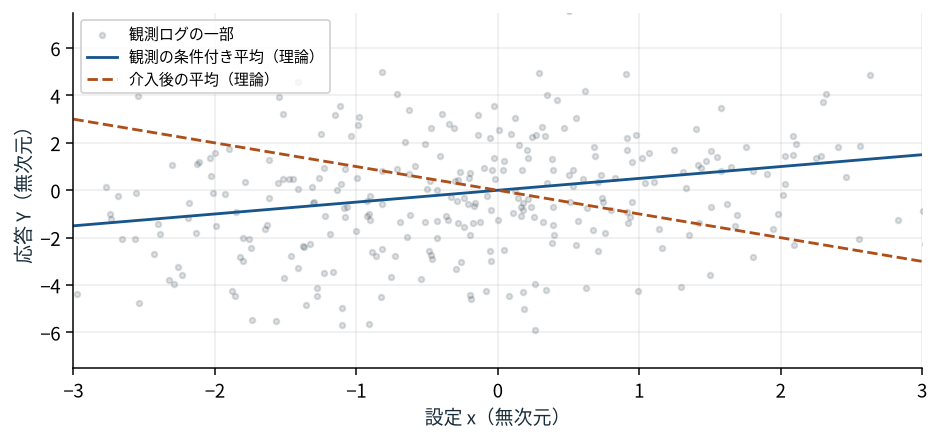

In [3]:
gen = torch.Generator().manual_seed(SEED + 200)
u, noise_x, noise_y = torch.randn((3, 5000), generator=gen)
observed_x = u + noise_x
observed_y = -observed_x + 3 * u + noise_y
design = torch.stack((torch.ones_like(observed_x), observed_x), dim=1)
intercept, observed_slope = torch.linalg.lstsq(design, observed_y).solution
assert abs(observed_slope.item() - 0.5) < 0.08

x = torch.linspace(-3, 3, 121)
fig, ax = plt.subplots(figsize=(6.85, 3.15), layout="constrained")
ax.scatter(observed_x[:300], observed_y[:300], s=9, color=INK, alpha=0.15, label="観測ログの一部")
ax.plot(x, 0.5 * x, color=BLUE, label="観測の条件付き平均（理論）")
ax.plot(x, -x, color=ORANGE, linestyle="--", label="介入後の平均（理論）")
ax.set(xlabel="設定 x（無次元）", ylabel="応答 Y（無次元）", xlim=(-3, 3), ylim=(-7.5, 7.5))
ax.legend(loc="upper left", fontsize=8)
save_figure(fig, "ch11_causal_contrast")

metrics = {
    "pareto": [name for name, keep in zip(names, pareto) if keep],
    "hypervolume": volume, "gain_d": gain,
    "context_policy": policy.tolist(), "contextual_reward": conditional_utility,
    "fixed_reward": fixed_action_utility, "observational_slope": observed_slope.item(),
    "observational_expected_slope": 0.5, "intervention_slope": -1.0,
}
(QUALITY / "ch11_metrics.json").write_text(json.dumps(metrics, indent=2) + chr(10), encoding="utf-8")